# Macao Tourism Recovery and Overall Unemployment 2020 to 2025

This notebook reproduces the revised Assignment 02 preliminary analysis. It reads the two original Macao DSEC workbooks, converts monthly visitor arrivals to calendar-quarter totals, selects non-overlapping calendar-quarter unemployment periods, validates the merged data, and creates the proposal statistics and figures.

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

base = Path.cwd()
visitor_file = base / 'Monthly Visitor Arrivals in Macau.xls'
unemployment_file = base / 'Overall Unemployment Rate in Macau.xls'
visitor_file, unemployment_file

(WindowsPath('F:/UM Courses/CISC7204/cisc7204-assgn02-2026-MC642923/Module05/ProjectProposal/Monthly Visitor Arrivals in Macau.xls'),
 WindowsPath('F:/UM Courses/CISC7204/cisc7204-assgn02-2026-MC642923/Module05/ProjectProposal/Overall Unemployment Rate in Macau.xls'))

## Load and aggregate monthly visitor arrivals

In [2]:
visitor = pd.read_excel(visitor_file, sheet_name='tmpF50E', header=None, engine='xlrd').iloc[10:, :3].copy()
visitor.columns = ['Year', 'Month', 'Visitor_arrivals']
visitor['Year'] = pd.to_numeric(visitor['Year'], errors='coerce').ffill()
visitor['Visitor_arrivals'] = pd.to_numeric(visitor['Visitor_arrivals'], errors='coerce')
visitor = visitor[visitor['Year'].notna() & visitor['Month'].notna()].copy()
visitor['Year'] = visitor['Year'].astype(int)
month_num = {'Jan.':1,'Feb.':2,'Mar.':3,'Apr.':4,'May':5,'Jun.':6,'Jul.':7,'Aug.':8,'Sept.':9,'Oct.':10,'Nov.':11,'Dec.':12}
visitor['Month_num'] = visitor['Month'].map(month_num)
visitor['Quarter_num'] = ((visitor['Month_num'] - 1) // 3 + 1).astype(int)
visitor_q = (visitor[visitor['Year'].between(2020, 2025)]
             .groupby(['Year','Quarter_num'], as_index=False)
             .agg(Visitor_arrivals=('Visitor_arrivals','sum'), Months=('Visitor_arrivals','count')))
visitor_q.head()

,Year,Quarter_num,Visitor_arrivals,Months
0,2020,1,3219170,3
1,2020,2,49730,3
2,2020,3,750204,3
3,2020,4,1877744,3
4,2021,1,1738428,3


## Select calendar-quarter unemployment periods

In [3]:
unemployment = pd.read_excel(unemployment_file, sheet_name='tmp6264', header=None, engine='xlrd').iloc[5:364, :3].copy()
unemployment.columns = ['Year', 'Period', 'Overall_unemployment_rate']
unemployment['Year'] = pd.to_numeric(unemployment['Year'], errors='coerce').ffill()
unemployment['Overall_unemployment_rate'] = pd.to_numeric(unemployment['Overall_unemployment_rate'], errors='coerce')
unemployment = unemployment[unemployment['Year'].notna() & unemployment['Period'].notna()].copy()
unemployment['Year'] = unemployment['Year'].astype(int)

def calendar_quarter(period):
    match = re.fullmatch(r'\s*(\d{1,2})/(\d{4})\s*-\s*(\d{1,2})/(\d{4})\s*', str(period))
    if not match:
        return None
    start_month, start_year, end_month, end_year = map(int, match.groups())
    if start_year != end_year:
        return None
    return {(1,3):1, (4,6):2, (7,9):3, (10,12):4}.get((start_month, end_month))

unemployment['Quarter_num'] = unemployment['Period'].map(calendar_quarter)
unemployment_q = unemployment[unemployment['Year'].between(2020, 2025) & unemployment['Quarter_num'].notna()][['Year','Quarter_num','Overall_unemployment_rate','Period']].copy()
unemployment_q['Quarter_num'] = unemployment_q['Quarter_num'].astype(int)
unemployment_q.head()

,Year,Quarter_num,Overall_unemployment_rate,Period
287,2020,1,2.1,1/2020 - 3/2020
290,2020,2,2.5,4/2020 - 6/2020
293,2020,3,2.9,7/2020 - 9/2020
296,2020,4,2.7,10/2020 - 12/2020
299,2021,1,2.9,1/2021 - 3/2021


## Merge and validate the 24-quarter dataset

In [4]:
data = visitor_q.merge(unemployment_q, on=['Year','Quarter_num'], validate='one_to_one')
data = data.sort_values(['Year','Quarter_num']).reset_index(drop=True)
data['Quarter'] = data['Year'].astype(str) + ' Q' + data['Quarter_num'].astype(str)
data['Visitor_arrivals_million'] = data['Visitor_arrivals'] / 1_000_000
checks = {
    'Matched quarters': len(data),
    'All quarters contain three visitor months': bool(data['Months'].eq(3).all()),
    'Missing analytical values': int(data[['Visitor_arrivals','Overall_unemployment_rate']].isna().sum().sum()),
    'Duplicate quarter keys': int(data.duplicated(['Year','Quarter_num']).sum())
}
assert checks == {'Matched quarters': 24, 'All quarters contain three visitor months': True, 'Missing analytical values': 0, 'Duplicate quarter keys': 0}
checks, data[['Quarter','Visitor_arrivals','Overall_unemployment_rate']].head()

({'Matched quarters': 24,
  'All quarters contain three visitor months': True,
  'Missing analytical values': 0,
  'Duplicate quarter keys': 0},
    Quarter  Visitor_arrivals  Overall_unemployment_rate
 0  2020 Q1           3219170                        2.1
 1  2020 Q2             49730                        2.5
 2  2020 Q3            750204                        2.9
 3  2020 Q4           1877744                        2.7
 4  2021 Q1           1738428                        2.9)

## Descriptive statistics and statistical relationship

In [5]:
x = data['Visitor_arrivals_million'].to_numpy()
y = data['Overall_unemployment_rate'].to_numpy()
r = np.corrcoef(x, y)[0, 1]
slope, intercept = np.polyfit(x, y, 1)
diff_r = data[['Visitor_arrivals_million','Overall_unemployment_rate']].diff().dropna().corr().iloc[0, 1]
summary = pd.DataFrame({
    'Measure': ['Matched quarters','Pearson r','R-squared','Slope per 1 million visitors','First-difference correlation'],
    'Value': [len(data), r, r**2, slope, diff_r]
})
summary

,Measure,Value
0,Matched quarters,24.000000
1,Pearson r,-0.805604
2,R-squared,0.648997
3,Slope per 1 million visitors,-0.147770
4,First-difference correlation,-0.513134


In [6]:
data[['Visitor_arrivals_million','Overall_unemployment_rate']].describe().round(3)

,Visitor_arrivals_million,Overall_unemployment_rate
count,24.000,24.000
mean,5.105,2.579
std,3.774,0.692
min,0.050,1.700
25%,1.805,1.900
50%,4.084,2.600
75%,8.909,2.950
max,10.453,4.000


## Time-series visualization

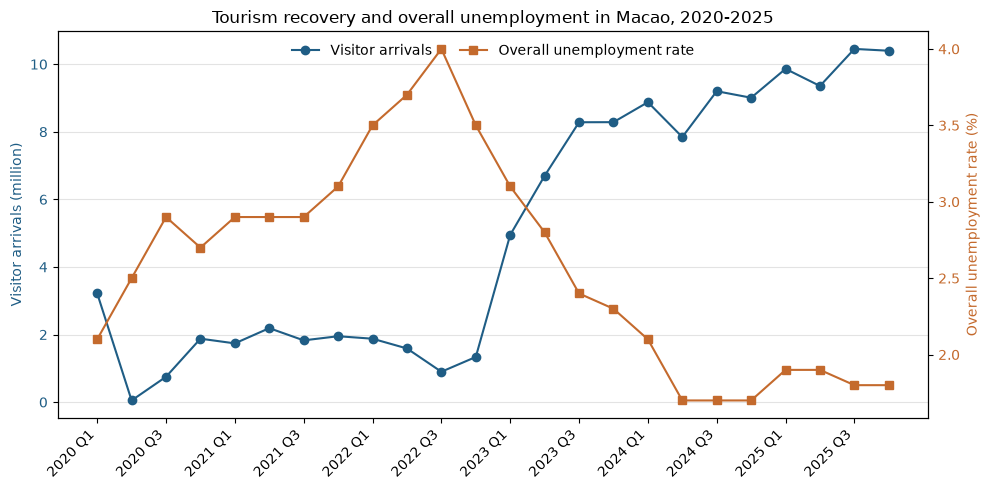

In [7]:
fig, ax1 = plt.subplots(figsize=(10, 5))
q = np.arange(len(data))
ax1.plot(q, x, color='#1F5D85', marker='o', label='Visitor arrivals')
ax1.set_ylabel('Visitor arrivals (million)', color='#1F5D85')
ax1.tick_params(axis='y', labelcolor='#1F5D85')
ax2 = ax1.twinx()
ax2.plot(q, y, color='#C46A2D', marker='s', label='Overall unemployment rate')
ax2.set_ylabel('Overall unemployment rate (%)', color='#C46A2D')
ax2.tick_params(axis='y', labelcolor='#C46A2D')
ax1.set_xticks(q[::2], data['Quarter'].iloc[::2], rotation=45, ha='right')
ax1.grid(True, axis='y', color='#E3E3E3')
ax1.set_title('Tourism recovery and overall unemployment in Macao, 2020-2025')
lines = ax1.get_lines() + ax2.get_lines()
ax1.legend(lines, [line.get_label() for line in lines], frameon=False, loc='upper center', ncol=2)
fig.tight_layout()
plt.show()

## Scatter plot and linear fit

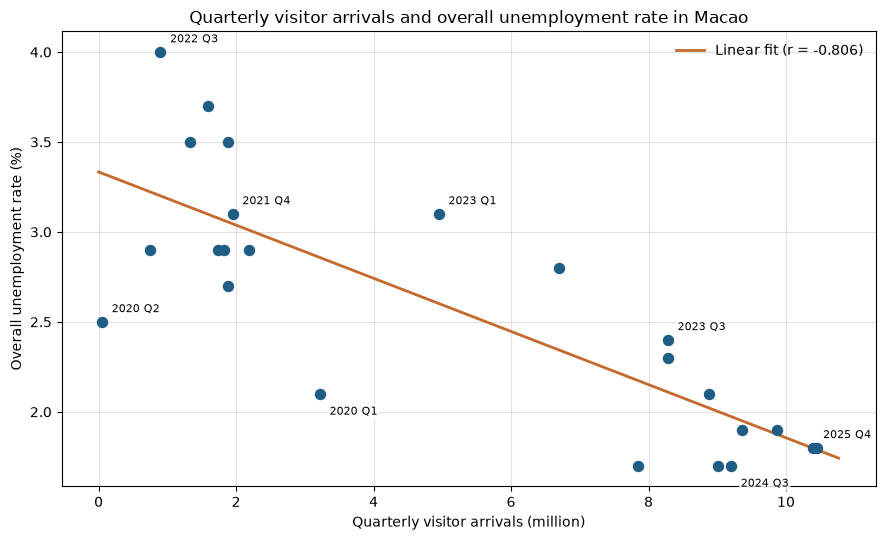

In [8]:
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.scatter(x, y, color='#1F5D85', s=52, zorder=3)
xx = np.linspace(0, x.max() * 1.03, 200)
ax.plot(xx, slope * xx + intercept, color='#C46A2D', linewidth=2, label=f'Linear fit (r = {r:.3f})')

# Label representative milestones only so the visual remains readable.
label_offsets = {
    '2020 Q1': (7, -15), '2020 Q2': (7, 7), '2021 Q4': (7, 7),
    '2022 Q3': (7, 7), '2023 Q1': (7, 7), '2023 Q3': (7, 7),
    '2024 Q3': (7, -15), '2025 Q4': (7, 7)
}
for _, row in data[data['Quarter'].isin(label_offsets)].iterrows():
    ax.annotate(
        row['Quarter'],
        (row['Visitor_arrivals_million'], row['Overall_unemployment_rate']),
        xytext=label_offsets[row['Quarter']], textcoords='offset points', fontsize=8,
        bbox=dict(boxstyle='round,pad=0.15', facecolor='white', edgecolor='none', alpha=0.8)
    )
ax.set_title('Quarterly visitor arrivals and overall unemployment rate in Macao')
ax.set_xlabel('Quarterly visitor arrivals (million)')
ax.set_ylabel('Overall unemployment rate (%)')
ax.grid(True, color='#D9D9D9', alpha=0.8)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

## Interpretation and limitations

The 24-quarter analysis shows a strong negative association between visitor arrivals and Macao's overall unemployment rate. The level correlation is approximately -0.806, while the first-difference correlation is weaker at approximately -0.513. The difference indicates that the shared pandemic and reopening trend explains part of the strong level relationship. The result does not establish causation. Border policy, seasonality, labour supply and the wider economic recovery affected both series. The overall unemployment rate covers the full labour force and should not be interpreted as a tourism-employment measure.